# Baseline results

Model 1 (TF-IDF and logistic regression), trained on D2 with an internal split. `python -m red_flag_detector.baseline` produces the files this notebook reads.

The threshold comes from the validation set. The test set and the Dating Stress Test each ran once with the chosen model.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from red_flag_detector.plots import BLUE, ORANGE, MUTED, apply_style, save

apply_style()
results = Path.cwd().parent / "results"
report = json.loads((results / "baseline_metrics.json").read_text())
pd.DataFrame(report["c_trials"]).round(3)

,C,threshold,train_seconds,precision,recall,f1,pr_auc
0,0.1,0.613,15.1,0.715,0.732,0.723,0.813
1,1.0,0.696,14.3,0.818,0.761,0.788,0.873
2,10.0,0.744,15.6,0.818,0.784,0.801,0.880


## Comments versus dating messages

In [2]:
stress = report["dating_stress_test"]
table = pd.DataFrame({
    "D2 test (online comments)": report["test"],
    "Dating test, core": stress["core"],
    "Dating test, core and stretch": stress["all"],
}).T[["precision", "recall", "f1"]].astype(float).round(3)
table["F1 95% interval"] = ["", *[f"{stress[k]['f1_95ci'][0]:.2f} to {stress[k]['f1_95ci'][1]:.2f}" for k in ("core", "all")]]
table.to_csv(results / "baseline_comparison.csv")
table

,precision,recall,f1,F1 95% interval
D2 test (online comments),0.810,0.767,0.788,
"Dating test, core",0.591,0.433,0.500,0.31 to 0.65
"Dating test, core and stretch",0.690,0.333,0.449,0.32 to 0.57


## What the model flags in each dating category

Left: higher is better. Right: lower is better.

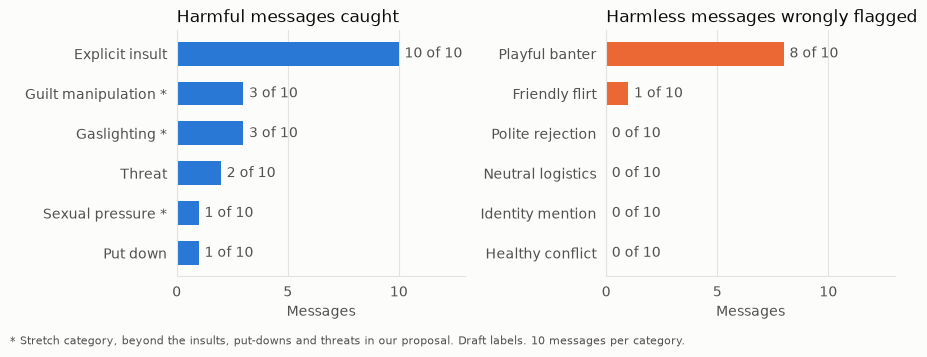

In [3]:
by_category = pd.read_csv(results / "dating_stress_test_by_category.csv")
by_category["name"] = by_category["category"].str.replace("_", " ").str.capitalize() + by_category["scope"].map({"core": "", "stretch": " *"})
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharex=True)
panels = [
    (axes[0], 1, BLUE, "Harmful messages caught"),
    (axes[1], 0, ORANGE, "Harmless messages wrongly flagged"),
]
for ax, label, colour, title in panels:
    part = by_category[by_category["label"] == label].sort_values(["flag_rate", "name"])
    bars = ax.barh(part["name"], part["flagged"], color=colour, height=0.6)
    ax.bar_label(bars, labels=[f"{f} of {m}" for f, m in zip(part["flagged"], part["messages"])], padding=4, color=MUTED)
    ax.set_title(title)
    ax.set_xlim(0, 13)
    ax.set_xticks([0, 5, 10])
    ax.set_xlabel("Messages")
    ax.grid(axis="y", visible=False)
fig.text(0, -0.03, "* Stretch category, beyond the insults, put-downs and threats in our proposal. Draft labels. 10 messages per category.", color=MUTED, fontsize=8)
fig.tight_layout()
save(fig, results / "dating_stress_test_by_category.png")

## Mistakes on our own messages

In [4]:
errors = pd.read_csv(results / "dating_stress_test_errors.csv")
pd.set_option("display.max_colwidth", None)
errors[["category", "score", "flagged", "text"]].sort_values(["category", "score"])

,category,score,flagged,text
0,friendly_flirt,0.882,1,"you're kind of dangerously charming, you know"
1,gaslighting,0.129,0,"that never happened, you're imagining things again"
3,gaslighting,0.130,0,you remember it wrong like you always do
2,gaslighting,0.195,0,"i never said that, you always twist my words"
5,gaslighting,0.245,0,"nobody else has a problem with me, so it must be you"
6,gaslighting,0.285,0,"i didn't do anything, you just get paranoid"
4,gaslighting,0.488,0,"you know you sound insane right now, right?"
7,gaslighting,0.532,0,if you weren't so emotional you'd see i'm right
8,guilt_manipulation,0.014,0,after everything i've done for you this is how you treat me
13,guilt_manipulation,0.063,0,why were you online and not answering me? who were you talking to
